# Philippine Housing Price Estimator

## Modelling Notebook

### Data Loading and Initial EDA

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Others
import os
import re

sns.set_theme(
    style='darkgrid',
    context='notebook',
    palette='deep'
)
sns.despine()

<Figure size 640x480 with 0 Axes>

In [2]:
data = os.path.dirname(os.getcwd())
data = os.path.join(data, 'data/raw/')

df = pd.read_csv(os.path.join(data, 'PH_Housing.csv'))

#### Data Overview

In [3]:
df.sample(n=5, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
1006,1007,FOR SALE PRE-SELLING TRIPLEX HOUSE AND LOT IN ...,"Pilar, Las Pinas",8600000.0,3.0,3.0,130.0,80.0,14.425263,121.005866
1220,1221,460sqm 5BR Bnew Modern House for sale in Santa...,"Santa Ana, Taytay",42500000.0,5.0,5.5,460.0,300.0,14.565423,121.126800
197,198,4BR 2-Storey House and Lot for Sale in Cabanat...,"Emilio Vergara Hwy Santa Arcadia, Cabanatuan",8686000.0,4.0,3.0,85.0,141.0,15.468244,120.976414
737,738,3-Bedroom Townhouse with Roof Deck for Sale at...,Lot 2-A Benefits Corner Dividend Street Projec...,12800000.0,3.0,3.0,165.0,52.0,14.672038,121.017908
120,121,2BR Single Attached House and Lot for Sale in ...,"Eden, Mexico",3970000.0,2.0,2.0,59.0,88.0,15.126253,120.658013


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HouseID      1500 non-null   int64  
 1   Description  1500 non-null   str    
 2   Location     1497 non-null   str    
 3   Price        1451 non-null   float64
 4   Bedrooms     1437 non-null   float64
 5   Bathrooms    1420 non-null   float64
 6   Floor Area   1463 non-null   float64
 7   Land Area    1477 non-null   float64
 8   Latitude     1500 non-null   float64
 9   Longitude    1500 non-null   float64
dtypes: float64(7), int64(1), str(2)
memory usage: 278.2 KB


In [5]:
df.describe()

,HouseID,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
count,1500.000000,1.451000e+03,1437.000000,1420.000000,1463.000000,1477.000000,1500.000000,1500.000000
mean,750.500000,3.282218e+07,3.617954,3.003169,213.925769,274.174001,14.166182,121.251438
std,433.157015,1.012451e+08,1.374068,1.854035,236.604564,889.539881,1.848612,1.048096
min,1.000000,3.000000e+05,1.000000,1.000000,22.000000,27.000000,6.128079,119.861430
25%,375.750000,4.902000e+06,3.000000,2.000000,67.550000,81.000000,14.330513,120.871001
50%,750.500000,9.200000e+06,3.000000,3.000000,142.000000,121.000000,14.523042,121.026941
75%,1125.250000,2.500000e+07,4.000000,4.000000,250.000000,240.000000,14.913178,121.085535
max,1500.000000,2.500000e+09,13.000000,43.000000,2200.000000,25000.000000,17.630468,125.803791


In [6]:
# Null values
df.isnull().sum()

HouseID         0
Description     0
Location        3
Price          49
Bedrooms       63
Bathrooms      80
Floor Area     37
Land Area      23
Latitude        0
Longitude       0
dtype: int64

In [7]:
# Duplicated values
df.duplicated().sum()

np.int64(0)

The dataset contains 1500 rows and 10 columns of which two are strings and the rest are integer and float. The columns that are strings contains the description of the house and its location. The bedrooms, bathrooms, floor area, land area will be directly useful in predicting the price of the house. The latitude and longitude will be used for clustering to classify the property locations.

There are several columns with null values which will be examined later. There are no duplicate data.

## Exploratory Data Analysis

### Univariate Analysis

#### Price Distribution

<Axes: xlabel='Price', ylabel='Count'>

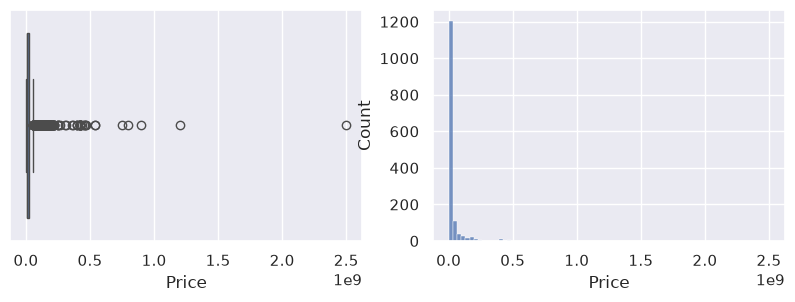

In [8]:
# Check Price distribution
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=df['Price'], ax=ax[0])
sns.histplot(x=df['Price'], ax=ax[1])

The distribution is very skewed to the right, meaning there are very large outliers present in the dataset. This must be handled well.

In [9]:
upper_price_lim = df['Price'].quantile(0.75)
num_upper_outlier = len(df.loc[df['Price'] > upper_price_lim])
print('Threshold amount for the upper outliers:', upper_price_lim)
print('Number of upper outliers:', num_upper_outlier)
print('Percent upper outlier: {:.2f}%'.format(num_upper_outlier / len(df.loc[df['Price'].notna()]) * 100))

Threshold amount for the upper outliers: 25000000.0
Number of upper outliers: 354
Percent upper outlier: 24.40%


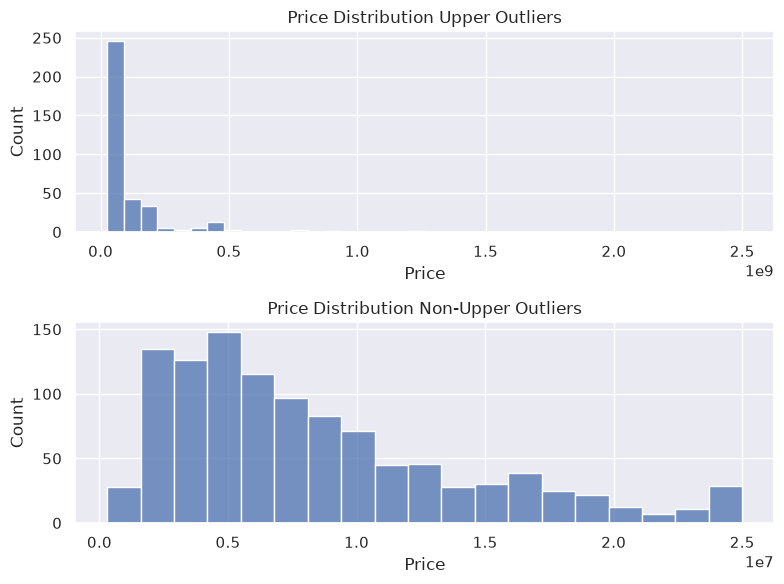

In [10]:
# Check distribution of outliers and non outliers
fig, ax = plt.subplots(2, 1, figsize=(8, 6))
sns.histplot(x=df.loc[df['Price'] > upper_price_lim]['Price'], ax=ax[0])
ax[0].set_title('Price Distribution Upper Outliers')

sns.histplot(x=df.loc[df['Price'] <= upper_price_lim]['Price'], ax=ax[1])
ax[1].set_title('Price Distribution Non-Upper Outliers')

plt.tight_layout()

In [11]:
# Check a sample of upper outliers
upper = df.loc[df['Price'] > upper_price_lim]
upper.sample(10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
1261,1262,For Sale 3-BR Bungalow House at Moonville Subd...,"Sun Valley, Paranaque",38000000.0,3.0,3.0,417.0,472.0,14.488841,121.032517
974,975,5 Bedroom House w/ Vacant Lot in Sto. Niño Vil...,"Dove Street, Banilad, Mandaue City Banilad, Ma...",50000000.0,5.0,5.0,300.0,852.0,10.348065,123.920123
791,792,San Lorenzo Village 2 Storey House 5 Bedroom f...,"San Lorenzo, Makati",200000000.0,5.0,5.0,NaN,470.0,14.550877,121.020783
713,714,6 Bedroom Ultra Modern House and Lot in Ayala ...,"Ayala Alabang, Muntinlupa",540000000.0,6.0,6.0,987.0,1442.0,14.422610,121.026941
1016,1017,Magnificent 5BR House in Ayala Alabang Village...,"Ayala Alabang, Muntinlupa",420000000.0,5.0,6.0,1600.0,868.0,14.422610,121.026941
1079,1080,Ultramodern Luxury Home in Ayala Alabang villa...,"Ayala Alabang, Muntinlupa",460000000.0,7.0,7.0,1500.0,900.0,14.422610,121.026941
1254,1255,For Sale Ancestral House & Lot Circa 1928 Earn...,"Sampaloc, Manila",27000000.0,6.0,6.0,NaN,180.0,14.603140,120.993417
333,334,3BR 3-Storey Townhouse for Sale near Alabang i...,"Km. 19 West Service Rd. Cupang, Muntinlupa",28678000.0,3.0,3.0,219.3,91.0,14.430274,121.045259
845,846,Alvendia By Rockwell Townhouse for Sale in San...,"Santa Lucia, San Juan",40000000.0,3.0,3.0,272.0,NaN,14.597872,121.035164
682,683,Brand New Modern Industrial Design House For S...,"Cabilang Baybay, Carmona",105000000.0,5.0,5.0,565.0,915.0,14.317501,121.051212


In [12]:
# Check the data for houses with the highes prices
upper[['Description', 'Location', 'Price']].sort_values(by='Price', ascending=False).head(20)

,Description,Location,Price
1369,Fully Furnished House and Lot for Sale in Forb...,"Forbes Park, Makati, National Capital Region, ...",2.500000e+09
753,Billion Peso Mansion Estate for sale at Tivoli...,"Batasan Hills, Quezon City",1.200000e+09
1352,5 Bedroom Mansion for sale in Ayala Alabang Vi...,"Ayala Alabang, Muntinlupa",9.000000e+08
1241,Exquisite Modern Designer House in Urdaneta Vi...,"Urdaneta, Makati",8.000000e+08
793,House and Lot For Sale with Pool at Dasmariñas...,"Dasmarinas, Makati",7.500000e+08
713,6 Bedroom Ultra Modern House and Lot in Ayala ...,"Ayala Alabang, Muntinlupa",5.400000e+08
1207,Luxury Brand New 6BR House and Lot for Sale in...,Ayala Alabang Muntinlupa Metro Manila Ayala Al...,5.400000e+08
715,Brand New House For Sale in Ayala Alabang Vill...,"Ayala Alabang, Muntinlupa",4.700000e+08
1079,Ultramodern Luxury Home in Ayala Alabang villa...,"Ayala Alabang, Muntinlupa",4.600000e+08
1148,Smart Home with Elevator for Sale in Ayala Ala...,"Ayala Alabang, Muntinlupa",4.600000e+08


The data for very large house prices are observed to also have significantly large features such as number of bedrooms, bathrooms, and area. This means that the data is realistic and not a human error. The data will be preserved and used for modelling. This is actually realistic since there are houses of the elite that will cost this much up.

In data modelling, log transform will be used due to the skewness of this data.

#### Floor and Land Area Distribution

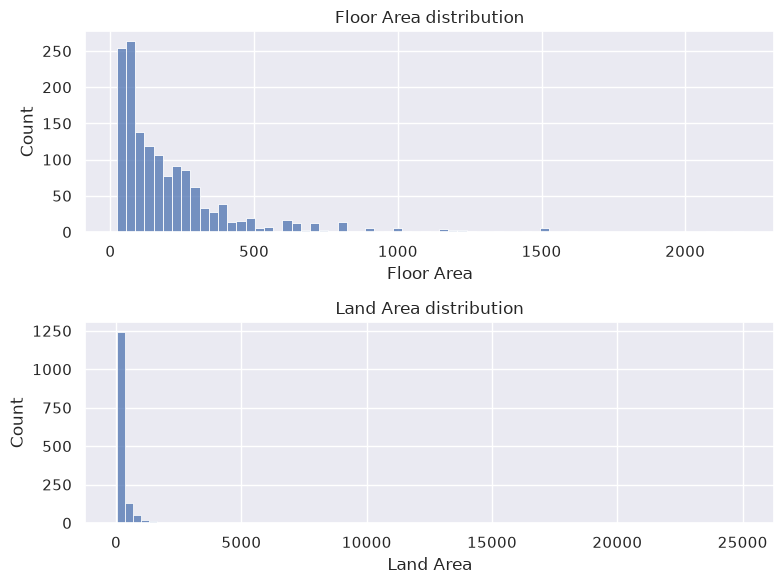

In [13]:
# Floor and Land Area Distribution
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.histplot(df['Floor Area'], ax=ax[0])
ax[0].set_title('Floor Area distribution')

sns.histplot(df['Land Area'], ax=ax[1])
ax[1].set_title('Land Area distribution')

plt.tight_layout()

There are also outliers for floor and land area. Lets examine these data

In [14]:
upp_land = df['Land Area'].quantile(0.75)
upp_floor = df['Floor Area'].quantile(0.75)

upp_area = df.loc[(df['Land Area'] > upp_land) | (df['Floor Area'] > upp_floor)]
print('Number of properties with areas that are outliers:', len(upp_area))
print('Percentage: {:.2f}%'.format(len(upp_area) / len(df.loc[(df['Floor Area'].notna()) | (df['Land Area'].notna())]) * 100))

Number of properties with areas that are outliers: 459
Percentage: 30.72%


In [15]:
upp_area.sample(10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
599,600,Exclusive House and Lot for Sale at Brizlane R...,"Cenacle Rd, 1128 Quezon City, Philippines Culi...",19495000.0,5.0,4.0,312.0,94.0,14.664747,121.044367
668,669,4 Bedroom House and Lot For Sale at Tierra Nue...,"Cupang, Muntinlupa",56000000.0,4.0,4.5,400.0,375.0,14.437884,121.050321
991,992,6 Bedroom House for Sale with Pool in Terrazas...,"Natipuan, Nasugbu",35000000.0,6.0,6.0,434.0,405.0,14.120002,120.623908
980,981,nice location modern single house and lot for...,"Marcelo Green Village, Paranaque, National Cap...",26000000.0,5.0,4.0,271.0,251.0,14.469644,121.040160
1426,1427,Single Detached Pre-owned House and Lot For Sa...,"Don Bosco, Paranaque",15500000.0,4.0,3.0,260.0,200.0,14.484330,121.031421
925,926,Newly painted House and Lot for Sale in Greenw...,"San Miguel, Pasig",26950000.0,5.0,NaN,500.0,362.0,14.565868,121.085557
1448,1449,L-R-1-1103 - Acquired Property for Sale in Lot...,"Calicanto, Batangas City",4308966.0,NaN,NaN,185.4,346.0,13.764829,121.055784
728,729,"4 Bedrooms House and Lot in 186 Averilla, San ...","186 Averilla St., San Juan City Little Baguio,...",42000000.0,4.0,5.0,280.0,100.0,14.597523,121.033830
683,684,5Bedrooms for Sale in Brizlane Residences Tand...,"Cenacle Rd, 1128 Quezon City, Philippines Culi...",19495000.0,5.0,4.0,312.0,98.0,14.664747,121.044367
998,999,For Sale: Brand New House and Lot with Best Vi...,"Matandang Balara, Quezon City",168000000.0,5.0,5.0,820.0,480.0,14.671680,121.074534


In [16]:
upp_area.sort_values(by='Floor Area', ascending=False).head(10)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
1477,1478,Villa House 11 bedroom in Pulu Amsic Subdivisi...,"Apo Street, Pulu Amsic Subdivision Amsic, Angeles",2.200000e+08,11.0,12.0,2200.0,1399.0,15.158929,120.569209
1369,1370,Fully Furnished House and Lot for Sale in Forb...,"Forbes Park, Makati, National Capital Region, ...",2.500000e+09,5.0,7.0,2100.0,1525.0,14.546560,121.037613
1165,1166,House For Sale in Ayala Alabang Muntinlupa City.,"Muntinlupa, National Capital Region, Philippin...",4.200000e+08,5.0,6.0,1600.0,868.0,14.410427,121.039888
1016,1017,Magnificent 5BR House in Ayala Alabang Village...,"Ayala Alabang, Muntinlupa",4.200000e+08,5.0,6.0,1600.0,868.0,14.422610,121.026941
1276,1277,5 level house House and Lot for Sale in Maria ...,"Maria Luisa Estate Park Cebu City Budla-An, Cebu",2.200000e+08,10.0,7.0,1522.0,735.0,10.361307,123.895694
1154,1155,Modern Futuristic home 7 bedroom for sale in a...,"Ayala Alabang, Muntinlupa",NaN,7.0,7.0,1500.0,900.0,14.422610,121.026941
1079,1080,Ultramodern Luxury Home in Ayala Alabang villa...,"Ayala Alabang, Muntinlupa",4.600000e+08,7.0,7.0,1500.0,900.0,14.422610,121.026941
715,716,Brand New House For Sale in Ayala Alabang Vill...,"Ayala Alabang, Muntinlupa",4.700000e+08,7.0,7.0,1500.0,900.0,14.422610,121.026941
1005,1006,For Sale Luxury House in Jardine de Busay w/ P...,"Busay, Cebu",1.200000e+08,5.0,9.0,1500.0,1458.0,9.917291,123.429455
774,775,For Sale Luxurious Mansion in Ayala Alabang Vi...,"Ayala Alabang, Muntinlupa",NaN,7.0,7.0,1500.0,900.0,14.422610,121.026941


In [17]:
upp_area.sort_values(by='Land Area', ascending=False).head(10)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
621,622,For Sale - Breathtaking Beach House in Calatag...,Calatagan,NaN,8.0,NaN,NaN,25000.0,13.832988,120.632236
1468,1469,L-R-1-190- Acquired Property for Sale in Lot 3...,"Awai, San Jacinto",5.142000e+06,NaN,NaN,71.0,10000.0,16.095645,120.481035
900,901,"Rest House farm for sale in Maligaya, Dinalupi...","Maligaya, Dinalupihan",1.400000e+07,4.0,3.0,200.0,10000.0,14.862591,120.426405
899,900,"Rest House farm for sale in Maligaya, Dinalupi...","Maligaya, Dinalupihan",1.400000e+07,4.0,3.0,200.0,10000.0,14.862591,120.426405
753,754,Billion Peso Mansion Estate for sale at Tivoli...,"Batasan Hills, Quezon City",1.200000e+09,5.0,7.0,1024.0,8000.0,14.686258,121.099335
1110,1111,"Single Bungalow Resthouse for Sale in Hermosa,...","Brgy. Mabiga, Hermosa, Bataan Mabiga, Hermosa",2.800000e+07,3.0,3.0,500.0,7624.0,14.817594,120.390179
1249,1250,For Sale: White Sand Beach House Property in D...,"Canlucani, Dapitan City, Zamboanga Peninsula, ...",NaN,2.0,6.0,300.0,5300.0,8.706211,123.425974
714,715,House and Lot For Sale Along National Highway ...,"Junob, Dumaguete",6.500000e+07,8.0,5.0,1000.0,3289.0,9.295849,123.283357
1007,1008,4 Bedroom House & Lot w/ Treated Bamboo Guest ...,"Liptong, Bacong",1.200000e+07,4.0,3.0,300.0,3267.0,9.261889,123.245437
746,747,Siargao Beach Front Villas For Sale in General...,"Poblacion V, General Luna",2.500000e+08,4.0,3.0,200.0,3000.0,14.133337,120.904197


The outliers for the area are similar with those prices. This are realistic figures that occur in the real world. The number of rooms and prices are relative to this observation. These data will be kept and used in modelling.

Log transform will also be used during data modelling for this data since it is skewed.

#### Number of Rooms

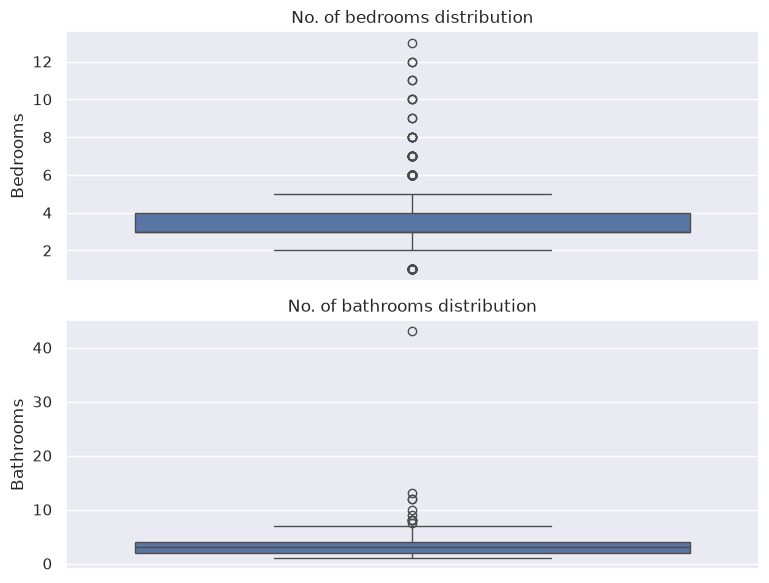

In [18]:
# Check number of rooms distribution
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.boxplot(df['Bedrooms'], ax=ax[0])
ax[0].set_title('No. of bedrooms distribution')

sns.boxplot(df['Bathrooms'], ax=ax[1])
ax[1].set_title('No. of bathrooms distribution')

plt.tight_layout()

There are outlier for the number of bedroom and bathroom. The 75th quantiles for both of these are 4 and this is realistic. We will set a higher upper threshold that is likely unusual.

In [19]:
upp_bed = 7
upp_bath = 7

upp_room = df.loc[(df['Bedrooms'] > upp_bed) | (df['Bathrooms'] > upp_bath)]
print('No. of properties with room outliers:', len(upp_room))
print('Percentage: {:.2f}%'.format(len(upp_room) / len(df.loc[(df['Bedrooms'].notna()) | (df['Bathrooms'].notna())]) * 100))

No. of properties with room outliers: 22
Percentage: 1.52%


In [20]:
upp_room.sample(10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
62,63,Residential House and Lot near Ayala for Sale ...,"San Antonio, Makati",NaN,12.0,8.0,500.0,1032.0,14.562156,121.008609
893,894,Loyola Grand Villas 13 Bedrooms for Sale,"Loyola Heights, Quezon City",120000000.0,13.0,13.0,1250.0,1000.0,14.641090,121.073778
553,554,Corner Commercial House & Lot for sale in Mans...,"Cpg Avenue Cor Katipunan Street Mansasa, Tagbi...",40000000.0,10.0,8.0,NaN,1574.0,9.636691,123.862074
1477,1478,Villa House 11 bedroom in Pulu Amsic Subdivisi...,"Apo Street, Pulu Amsic Subdivision Amsic, Angeles",220000000.0,11.0,12.0,2200.0,1399.0,15.158929,120.569209
1005,1006,For Sale Luxury House in Jardine de Busay w/ P...,"Busay, Cebu",120000000.0,5.0,9.0,1500.0,1458.0,9.917291,123.429455
1492,1493,7 Carport Elegant Modern Contemporary House an...,"Dalig, Antipolo",65000000.0,8.0,7.0,670.0,555.0,14.573045,121.186472
1043,1044,For Sale- 3 Storey Residential House & Lot at ...,"Salitran Iv, Dasmarinas",30000000.0,6.0,8.0,650.0,300.0,14.343603,120.938254
1265,1266,For Sale: 315 sqm Pre-Owned Residential House ...,"West Crame, San Juan",28000000.0,8.0,4.0,420.0,315.0,14.606310,121.050265
1015,1016,House w/ Swimming Pool for Sale in Inner Circl...,"Almanza Uno, Las Pinas",73900000.0,8.0,5.0,548.0,662.0,14.424732,121.014573
707,708,"More Freebies,Preselling House for Sale in Mad...","Sindalan, San Fernando",7350000.0,4.0,43.0,135.0,164.0,15.078511,120.641521


In [21]:
upp_room.sort_values(by='Bedrooms', ascending=False).head(10)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
893,894,Loyola Grand Villas 13 Bedrooms for Sale,"Loyola Heights, Quezon City",120000000.0,13.0,13.0,1250.0,1000.0,14.641090,121.073778
62,63,Residential House and Lot near Ayala for Sale ...,"San Antonio, Makati",NaN,12.0,8.0,500.0,1032.0,14.562156,121.008609
475,476,Charming Loyola Grand Villas House and Lot for...,"Matandang Balara, Quezon City",110000000.0,12.0,12.0,1200.0,1000.0,14.671680,121.074534
945,946,PASAY HOUSE FOR SALE,"San Roque, Pasay",120000000.0,11.0,7.0,NaN,730.2,6.940629,122.039024
1477,1478,Villa House 11 bedroom in Pulu Amsic Subdivisi...,"Apo Street, Pulu Amsic Subdivision Amsic, Angeles",220000000.0,11.0,12.0,2200.0,1399.0,15.158929,120.569209
553,554,Corner Commercial House & Lot for sale in Mans...,"Cpg Avenue Cor Katipunan Street Mansasa, Tagbi...",40000000.0,10.0,8.0,NaN,1574.0,9.636691,123.862074
1276,1277,5 level house House and Lot for Sale in Maria ...,"Maria Luisa Estate Park Cebu City Budla-An, Cebu",220000000.0,10.0,7.0,1522.0,735.0,10.361307,123.895694
1117,1118,La Vista Corner House for Sale in Quezon City,"Pansol, Quezon City",308000000.0,10.0,10.0,1000.0,2055.0,14.652798,121.081524
1461,1462,[03673-C-175] House & Lot for sale in Jardin L...,"Lots 5, 6, 7 & 8 Jardin Leonila Subdivision Ba...",6643000.0,9.0,5.0,438.0,480.0,14.179208,121.252268
1145,1146,2 HOUSE & LOT /2 House property 9 BR 4 T&B 3 C...,"Ortigas Avenue, Pasig",16000000.0,9.0,4.0,190.0,240.0,14.588994,121.067869


In [22]:
upp_room.sort_values(by='Bathrooms', ascending=False).head(10)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
707,708,"More Freebies,Preselling House for Sale in Mad...","Sindalan, San Fernando",7350000.0,4.0,43.0,135.0,164.0,15.078511,120.641521
893,894,Loyola Grand Villas 13 Bedrooms for Sale,"Loyola Heights, Quezon City",120000000.0,13.0,13.0,1250.0,1000.0,14.641090,121.073778
475,476,Charming Loyola Grand Villas House and Lot for...,"Matandang Balara, Quezon City",110000000.0,12.0,12.0,1200.0,1000.0,14.671680,121.074534
1477,1478,Villa House 11 bedroom in Pulu Amsic Subdivisi...,"Apo Street, Pulu Amsic Subdivision Amsic, Angeles",220000000.0,11.0,12.0,2200.0,1399.0,15.158929,120.569209
1117,1118,La Vista Corner House for Sale in Quezon City,"Pansol, Quezon City",308000000.0,10.0,10.0,1000.0,2055.0,14.652798,121.081524
1005,1006,For Sale Luxury House in Jardine de Busay w/ P...,"Busay, Cebu",120000000.0,5.0,9.0,1500.0,1458.0,9.917291,123.429455
637,638,"Reduced For Sale : House in Ma. Luisa Estate, ...","Banilad, Cebu",65000000.0,6.0,8.0,918.0,566.0,10.346519,123.911112
62,63,Residential House and Lot near Ayala for Sale ...,"San Antonio, Makati",NaN,12.0,8.0,500.0,1032.0,14.562156,121.008609
553,554,Corner Commercial House & Lot for sale in Mans...,"Cpg Avenue Cor Katipunan Street Mansasa, Tagbi...",40000000.0,10.0,8.0,NaN,1574.0,9.636691,123.862074
1043,1044,For Sale- 3 Storey Residential House & Lot at ...,"Salitran Iv, Dasmarinas",30000000.0,6.0,8.0,650.0,300.0,14.343603,120.938254


The high number of bedrooms and bathrooms can be a commercial property, either a hotel or a dormitory. It can also be possible for luxury villas. We will preserve this values for the rooms except for the room with 43 bathrooms and only 4 bedrooms. This property is very unrealistic. This is only one data, so we can impute its number of bathrooms by simply using its number of bedrooms.

Standard Scaler will be used for this features during data modelling.

In [23]:
df.loc[df['Bathrooms'] == 43]

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
707,708,"More Freebies,Preselling House for Sale in Mad...","Sindalan, San Fernando",7350000.0,4.0,43.0,135.0,164.0,15.078511,120.641521


In [24]:
# Confirming that there is only one row for this, we can proceed to setting the value
df.loc[df['Bathrooms'] == 43, 'Bathrooms'] = 4
df.loc[df['HouseID'] == 708]

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
707,708,"More Freebies,Preselling House for Sale in Mad...","Sindalan, San Fernando",7350000.0,4.0,4.0,135.0,164.0,15.078511,120.641521


### Bivariate Analysis

In [25]:
# Duplicate dataframe
df_copy = df.copy()

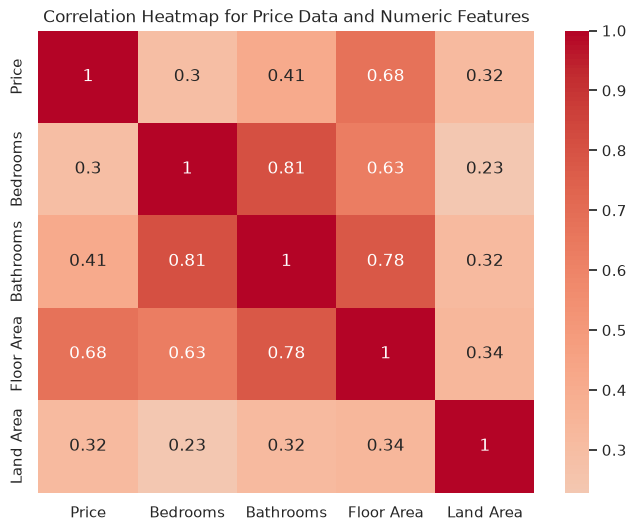

In [26]:
# Check correlation matrix between variables especially how they affect the price
corr = df_copy[['Price', 'Bedrooms', 'Bathrooms', 'Floor Area', 'Land Area']].corr(numeric_only=True)
plt.figure(figsize=(8,6))
heatmap = sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
heatmap.set_title('Correlation Heatmap for Price Data and Numeric Features')
plt.show()

The features all have positive correlation with the 'Price' with the 'Floor Area' having the strongest correlation. This means that generally, as the features increase, the price will also increase. The features also have strong positive correlation between each other with values 0.60+ with the exception of 'Land Area' which only has between 0.23 - 0.34 correlations with the others. 

####  Bathroom / Bedroom Ratio

We will compute bathroom / bedroom ratio since high ratio can signify luxury and be a signal for the price.

In [27]:
df_copy['BB Ratio'] = df_copy['Bathrooms'] / df_copy['Bedrooms']
df_copy.sample(5, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude,BB Ratio
1006,1007,FOR SALE PRE-SELLING TRIPLEX HOUSE AND LOT IN ...,"Pilar, Las Pinas",8600000.0,3.0,3.0,130.0,80.0,14.425263,121.005866,1.00
1220,1221,460sqm 5BR Bnew Modern House for sale in Santa...,"Santa Ana, Taytay",42500000.0,5.0,5.5,460.0,300.0,14.565423,121.126800,1.10
197,198,4BR 2-Storey House and Lot for Sale in Cabanat...,"Emilio Vergara Hwy Santa Arcadia, Cabanatuan",8686000.0,4.0,3.0,85.0,141.0,15.468244,120.976414,0.75
737,738,3-Bedroom Townhouse with Roof Deck for Sale at...,Lot 2-A Benefits Corner Dividend Street Projec...,12800000.0,3.0,3.0,165.0,52.0,14.672038,121.017908,1.00
120,121,2BR Single Attached House and Lot for Sale in ...,"Eden, Mexico",3970000.0,2.0,2.0,59.0,88.0,15.126253,120.658013,1.00


In [28]:
corr = df_copy[['Price', 'BB Ratio']].corr()
corr

,Price,BB Ratio
Price,1.000000,0.256276
BB Ratio,0.256276,1.000000


<Axes: xlabel='BB Ratio', ylabel='Price'>

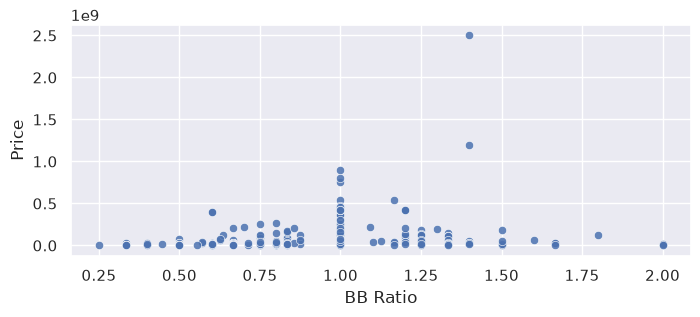

In [29]:
# Scatterplot

plt.figure(figsize=(8, 3))
sns.scatterplot(df_copy, x='BB Ratio', y='Price', alpha=0.85)

The Bathroom to Bedroom ratio shows no strong correlation but we will still use this engineered feature.

#### Floor to Land Area

Floor to land area can send signals such that it can signify a luxury mansion or villa with low floor to land area. It can also signal a cramped commercial or city space, or a house with several floors with high floor to land area.

In [30]:
df_copy['FL Ratio'] = df_copy['Floor Area'] / df_copy['Land Area']
df_copy.sample(5, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude,BB Ratio,FL Ratio
1006,1007,FOR SALE PRE-SELLING TRIPLEX HOUSE AND LOT IN ...,"Pilar, Las Pinas",8600000.0,3.0,3.0,130.0,80.0,14.425263,121.005866,1.00,1.625000
1220,1221,460sqm 5BR Bnew Modern House for sale in Santa...,"Santa Ana, Taytay",42500000.0,5.0,5.5,460.0,300.0,14.565423,121.126800,1.10,1.533333
197,198,4BR 2-Storey House and Lot for Sale in Cabanat...,"Emilio Vergara Hwy Santa Arcadia, Cabanatuan",8686000.0,4.0,3.0,85.0,141.0,15.468244,120.976414,0.75,0.602837
737,738,3-Bedroom Townhouse with Roof Deck for Sale at...,Lot 2-A Benefits Corner Dividend Street Projec...,12800000.0,3.0,3.0,165.0,52.0,14.672038,121.017908,1.00,3.173077
120,121,2BR Single Attached House and Lot for Sale in ...,"Eden, Mexico",3970000.0,2.0,2.0,59.0,88.0,15.126253,120.658013,1.00,0.670455


In [31]:
corr = df_copy[['Price', 'FL Ratio']].corr()
corr

,Price,FL Ratio
Price,1.00000,0.04408
FL Ratio,0.04408,1.00000


<Axes: xlabel='FL Ratio', ylabel='Price'>

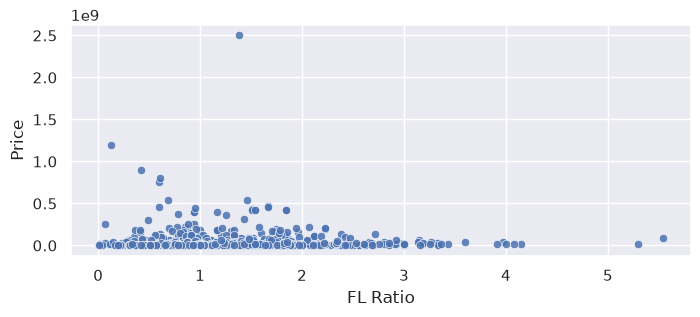

In [32]:
# Scatterplot

plt.figure(figsize=(8, 3))
sns.scatterplot(df_copy, x='FL Ratio', y='Price', alpha=0.85)

The correlation is also low for Floor to Land Area ratio but we will still use this during modelling.

#### Location

For location, we will extract the address and city (assume) from the column. Then we will analyze their average prices to get insights only, we will not use this directly as features for modelling since it will leak data to the model. Instead, target encoding will be done later which is the same process but only does it in the training data.

In [33]:
def parse_loc(location):
    if pd.isna(location):
        return 'missing', 'missing'
        
    parsed = [part.strip().lower() for part in location.split(',')]
    
    if len(parsed) >= 2:
        locality = parsed[-2]
        city = parsed[-1]
    elif len(parsed) == 1:
        locality = 'missing'
        city = parsed[-1]
    else:
        locality = 'missing'
        city = 'missing'

    return locality, city
    
df_copy[['Locality', 'City']] = df_copy['Location'].apply(lambda x: pd.Series(parse_loc(x)))

In [34]:
df_copy[['Locality', 'City']].nunique()

Locality    608
City        143
dtype: int64

It is observed that the number of categorical data in this two columns are huge, thus, it might be inefficient to do One Hot Encoding for this features. That is why target encoding will be made during modelling.

In [35]:
# Check price averages
df_copy['Locality Avg'] = df_copy.groupby('Locality')['Price'].transform('mean')
df_copy['Locality Count'] = df_copy.groupby('Locality')['Price'].transform('count')
df_copy['City Avg'] = df_copy.groupby('City')['Price'].transform('mean')
df_copy['City Count'] = df_copy.groupby('City')['Price'].transform('count')

In [36]:
# Check top cities
df_city_ranked = df_copy.groupby('City')[['City Avg', 'City Count']].first().sort_values(by=['City Avg', 'City Count'], ascending=False).reset_index()

In [37]:
df_city_ranked.describe()

,City Avg,City Count
count,1.390000e+02,143.000000
mean,1.789660e+07,10.146853
std,4.056755e+07,19.270483
min,3.000000e+05,0.000000
25%,3.910611e+06,1.000000
50%,6.800000e+06,3.000000
75%,1.594843e+07,9.500000
max,3.760556e+08,135.000000


In [38]:
df_city_ranked.head(10)

,City,City Avg,City Count
0,makati,3.760556e+08,18
1,general luna,2.500000e+08,1
2,muntinlupa,1.104312e+08,135
3,taguig,9.718366e+07,17
4,pasay,6.675000e+07,2
5,morong,6.500000e+07,1
6,quezon city,6.434451e+07,119
7,dumanjug,5.000000e+07,1
8,mandaue,5.000000e+07,1
9,pasig,4.668138e+07,29


<Axes: xlabel='City'>

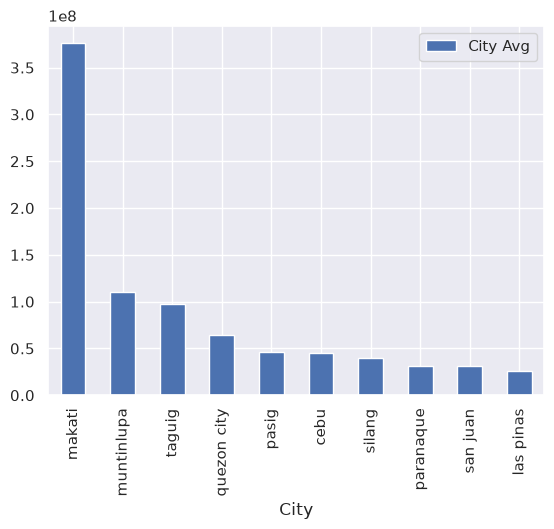

In [39]:
df_city_ranked.loc[df_city_ranked['City Count'] >= 10].head(10).plot(x='City', y='City Avg', kind='bar')

In [40]:
len(df_copy.loc[df_copy['City Count'] >= 10])

1189

The data shows that only around 25% of the cities have more than 10 data each but target encoding with smoothing will handle this for us. Also, 1189 of the data has a city with 10 or more listings, thus, a large part of the data is significant during target encoding. 

The top cities with more than 10 data are Makati, Muntinlupa, and Taguig. Most of this cities are in NCR. We can make a is_ncr feature for this.

In [41]:
# Check top localities
df_loc_ranked = df_copy.groupby('Locality')[['Locality Avg', 'Locality Count']].first().sort_values(by=['Locality Avg', 'Locality Count'], ascending=False).reset_index()

In [42]:
df_loc_ranked.describe()

,Locality Avg,Locality Count
count,5.870000e+02,608.000000
mean,3.114397e+07,2.386513
std,1.217598e+08,5.682159
min,3.000000e+05,0.000000
25%,4.337472e+06,1.000000
50%,9.000000e+06,1.000000
75%,2.000000e+07,2.000000
max,2.500000e+09,71.000000


In [43]:
df_loc_ranked.head(10)

,Locality,Locality Avg,Locality Count
0,philippines forbes park,2.500000e+09,1
1,urdaneta,8.000000e+08,1
2,dasmarinas,6.000000e+08,2
3,ayala alabang muntinlupa metro manila ayala al...,5.400000e+08,1
4,muntinlupa ayala alabang,4.200000e+08,1
5,philippines ayala alabang,4.200000e+08,1
6,ugong norte,3.650000e+08,2
7,bel-air,3.560000e+08,3
8,pansol,3.080000e+08,1
9,ayala alabang,2.839571e+08,35


In [44]:
len(df_copy.loc[df_copy['Locality Count'] >= 10])

495

It can be observed that Locality is very granular with 600 unique values for only 1500 rows of data. Also, 75% of the Locality only have 1 or 2 listings. This feature will be ignored as this might cause overfitting for the model.

In [45]:
# Area flag for NCR, Near NCR, Cebu. List for cities

ncr = [
    'caloocan',
    'las pinas',
    'makati',
    'malabon',
    'mandaluyong',
    'manila',
    'marikina',
    'muntinlupa',
    'navotas',
    'paranaque',
    'pateros',
    'pasay',
    'pasig',
    'quezon city',
    'san juan',
    'taguig',
    'valenzuela',
]

metro_cebu = [
    'cebu',
    'mandaue',
    'lapu-lapu',
    'consolacion',
    'talisay',
    'minglanilla',
    'apas',
    'lahug',
]

near_ncr = [
    # Cavite
    'silang',
    'carmona',
    'alfonso',
    'tagaytay',
    'dasmarinas',
    'bacoor',
    'general trias',
    'imus',
    'trece martires',
    'tanza',
    'kawit',
    'rosario',
    'naic',

    # Laguna
    'los banos',
    'cabuyao',
    'santa rosa',
    'sta rosa city laguna',
    'calamba',
    'binan',
    'san pablo',
    'pagsanjan',
    'pila',
    'lumban',
    'majayjay',
    'calauan',

    # Rizal
    'antipolo',
    'taytay',
    'cainta',
    'san mateo',
    'angono',
    'binangonan',
    'teresa',

    # Bulacan
    'san jose del monte',
    'marilao',
    'pulilan',
    'malolos',
    'baliuag',
    'plaridel',
    'santa maria',
    'meycauayan',
    'pandi',
    'hagonoy',
    'paombong',
    'san rafael',
    'bulacan',
]

In [46]:
# Make flags

df_copy['is_ncr'] = df_copy['City'].isin(ncr).astype(int)
df_copy['is_metro_cebu'] = df_copy['City'].isin(metro_cebu).astype(int)
df_copy['is_near_ncr'] = df_copy['City'].isin(near_ncr).astype(int)

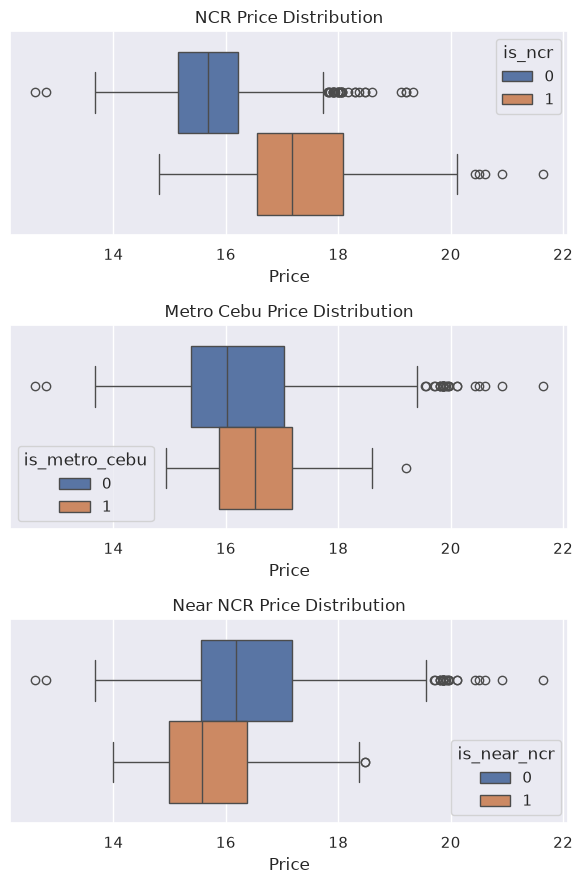

In [47]:
# Visualize Price Distribution
# Perform log transform first for the price for better visualization
df_vis_price = df_copy[['Price', 'is_ncr', 'is_metro_cebu', 'is_near_ncr']].copy()
df_vis_price['Price'] = np.log1p(df_vis_price['Price'])

fig, ax = plt.subplots(3, 1, figsize=(6, 9))

sns.boxplot(df_vis_price, x='Price', orient='h', hue='is_ncr', ax=ax[0])
ax[0].set_title('NCR Price Distribution')

sns.boxplot(df_vis_price, x='Price', orient='h', hue='is_metro_cebu', ax=ax[1])
ax[1].set_title('Metro Cebu Price Distribution')

sns.boxplot(df_vis_price, x='Price', orient='h', hue='is_near_ncr', ax=ax[2])
ax[2].set_title('Near NCR Price Distribution')

plt.tight_layout()

We can observe that there is a difference in the distribution for different flags and the average prices. We can use these flags for modelling.

#### Description

For the column Description, we will try to get as many useful signals as possible such as poperty type, model, amenities

In [48]:
# House type
house_types = ['mansion', 'beach house', 'rest house', 'bungalow', 'townhouse', 'villa', 'rowhouse', 'detached', 'attached', \
            'shophouse', 'duplex', 'triplex', 'condominium']

In [49]:
def parse_type(description):
    if pd.isna(description):
        return 'others'

    for house_type in house_types:
        match = re.search(rf'\b({re.escape(house_type)})s?\b', description, flags=re.IGNORECASE)
        if match:
            return house_type.lower()

    return 'others'

df_copy['house_type'] = df_copy['Description'].apply(parse_type)

In [50]:
df_copy['house_type'].value_counts()

house_type
others         990
townhouse      309
attached        50
duplex          40
detached        36
bungalow        24
villa           18
mansion          9
beach house      8
rowhouse         5
shophouse        4
triplex          3
condominium      2
rest house       2
Name: count, dtype: int64

In [51]:
df_house_type = df_copy.groupby('house_type')['Price'].agg('mean').reset_index().sort_values(by='Price', ascending=False)

<Axes: xlabel='house_type'>

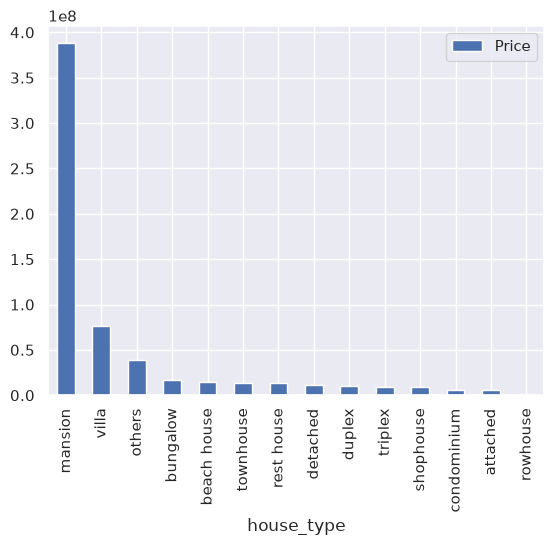

In [52]:
df_house_type.plot(x='house_type', y='Price', kind='bar')

As we can observed, there isa difference between the house types. We will use this in modelling but we will use one hot encoding for this feature. This is due to the relatively low counts per house type compared to the default type 'others'. Also, this is only a small number of category which is fine for modelling.

In [53]:
# Number of Stories

# Two storey
def parse_two_storey(description):
    if pd.isna(description):
        return 0

    description = description.lower()
    if re.search(r'2[-\s]?storeys?', description) or re.search(r'two[-\s]?storeys?', description):
        return 1
    else:
        return 0
        
df_copy['is_two_storey'] = df_copy['Description'].apply(parse_two_storey)

# Three storey
def parse_three_storey(description):
    if pd.isna(description):
        return 0

    description = description.lower()
    if re.search(r'3[-\s]?storeys?', description) or re.search(r'three[-\s]?storeys?', description):
        return 1
    else:
        return 0

df_copy['is_three_storey'] = df_copy['Description'].apply(parse_three_storey)

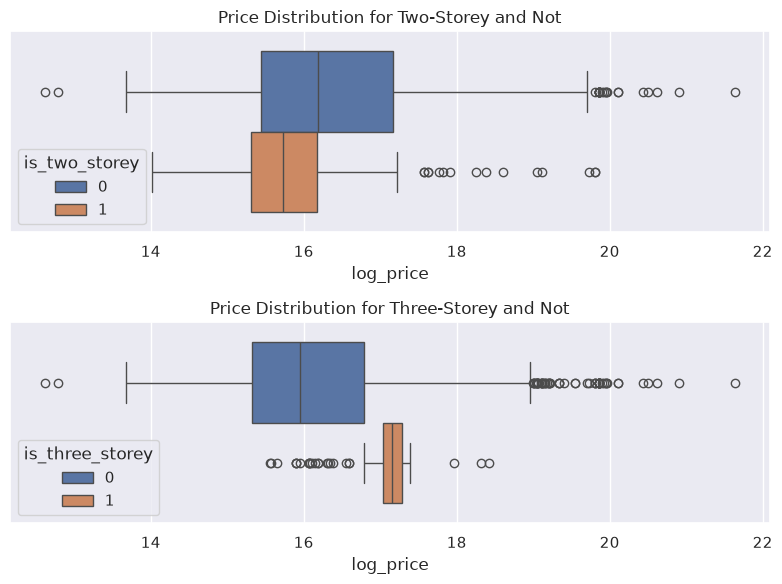

In [54]:
df_vis = df_copy[['Price', 'is_two_storey', 'is_three_storey']].copy()
df_vis['log_price'] = np.log1p(df_vis['Price'])

fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.boxplot(data=df_vis, x='log_price', hue='is_two_storey', ax=ax[0])
ax[0].set_title('Price Distribution for Two-Storey and Not')

sns.boxplot(data=df_vis, x='log_price', hue='is_three_storey', ax=ax[1])
ax[1].set_title('Price Distribution for Three-Storey and Not')

plt.tight_layout()

There are observable difference in the price distribution for different flags.

In [55]:
# Elite
# Most of the highest priced properties are from either forbes park or ayala alabang. We will use this information to make an is_elite flag

def parse_elite(row):
    if pd.isna(row['Description']) or pd.isna(row['Location']):
        return 0

    pattern_forbes = r'\bforbes park\b'
    pattern_ayala = r'\bayala alabang\b'

    description = row['Description'].lower()
    location = row['Location'].lower()

    if re.search(pattern_ayala, location, flags=re.IGNORECASE) or re.search(pattern_ayala, description, flags=re.IGNORECASE):
        return 1
    elif re.search(pattern_forbes, location, flags=re.IGNORECASE) or re.search(pattern_forbes, description, flags=re.IGNORECASE):
        return 1
    else:
        return 0

df_copy['is_elite'] = df_copy.apply(parse_elite, axis=1)

In [56]:
df_copy['is_elite'].value_counts()

is_elite
0    1454
1      46
Name: count, dtype: int64

In [57]:
df_copy.loc[df_copy['is_elite'] == 1][['Description', 'Location', 'Price']].head()

,Description,Location,Price
548,Affordable House and Lot For Sale near Ayala A...,"Alabang, Muntinlupa",10840000.0
559,For Sale: 5 Bedroom House and Lot for Sale in ...,"Ayala Alabang, Muntinlupa",139250000.0
601,New House and Lot For Sale in Enclave Alabang ...,"Almanza Dos, Las Pinas",150000000.0
645,"Brand New House for Sale in Ayala Alabang, Mun...","Ayala Alabang, Muntinlupa",170000000.0
650,5 Bedroom House For Sale in Ayala Alabang Vill...,"Ayala Alabang, Muntinlupa",400000000.0


Text(0.5, 1.0, 'Price Distribution for the Elite Houses vs Normal')

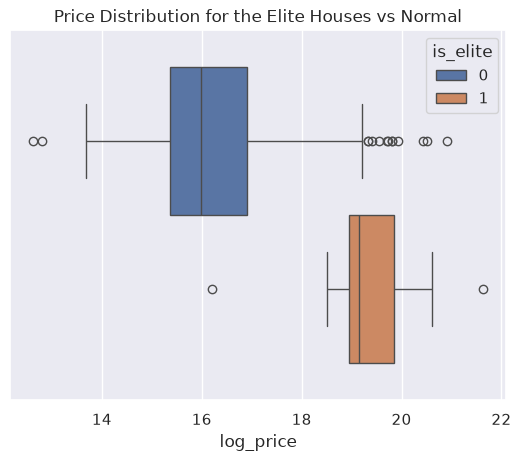

In [58]:
df_vis = df_copy[['Description', 'Location', 'Price', 'is_elite']].copy()
df_vis['log_price'] = np.log1p(df_vis['Price'])

sns.boxplot(data=df_vis, x='log_price', hue='is_elite', orient='h')
plt.title('Price Distribution for the Elite Houses vs Normal')

The gap between the distribution is very significant. We will keep this feature for the model.

In [59]:
# House Model
# Get the model names first

house_models = set()

for description in df_copy['Description']:
    if pd.isna(description):
        continue

    description = description.lower()
    
    potential_models = re.findall(r'\|\s*(\w+)\b', description)
    house_models.update(potential_models)

In [60]:
# Inspecting the set, lets create the set to ignore
minus_set = {'08', '1br', '1ds', '2', '2br', '3', '3br', '5', '5br', 'b1', 'bare', 'corner', 'end', 'five', 'flavorscapes', 'for', 'four', \
            'house', 'inner', 'las', 'mara', 'modern', 'north', 'p500', 'pag', 'pasig', 'parklane', 'pre', 'single', 'smart', 'spacious', \
            'the', 'typical', 'unit'}

# Remove the texts
house_models.difference_update(minus_set)

In [61]:
def parse_model(description):
    if pd.isna(description):
        return 'others'

    for model in house_models:
        if re.search(rf'\b({model})\b', description, flags=re.IGNORECASE):
            return model

    return 'others'

df_copy['house_model'] = df_copy['Description'].apply(parse_model)

In [62]:
df_copy['house_model'].value_counts()

house_model
others       1124
cara           46
freya          24
dani           23
ezabelle       20
             ... 
tahoe           1
pebble          1
tanglaw         1
ametta          1
margarita       1
Name: count, Length: 70, dtype: int64

The data for the house model is very sparse. One hot encoding is not efficient as it will create around 70 columns with very few 1s only. We will not include this feature in modelling.

In [63]:
# Amenities

In [64]:
def flag_ammenities(prefix, ammenity):
    col_name = f'{prefix}_{ammenity}'
    df_copy[col_name] = np.where(df_copy['Description'].str.contains(ammenity, case=False, na=False), 1, 0)

    print(df_copy.groupby(col_name)['Price'].agg(['mean', 'median', 'count']))
    print()

flag_ammenities('has', 'pool')
flag_ammenities('has', 'balcony')
flag_ammenities('has', 'gym')
flag_ammenities('has', 'elevator')
flag_ammenities('has', 'garage')
flag_ammenities('is', 'affordable')
flag_ammenities('is', 'luxury')
flag_ammenities('is', 'renovated')
flag_ammenities('is', 'smart')
flag_ammenities('is', 'beachfront')
flag_ammenities('is', 'overlooking')
flag_ammenities('is', 'contemporary')
flag_ammenities('is', 'modern')
flag_ammenities('is', 'foreclosed')
flag_ammenities('in', 'subdivision')

                  mean      median  count
has_pool                                 
0         3.086221e+07   8800000.0   1411
1         1.019600e+08  58500000.0     40

                     mean     median  count
has_balcony                                
0            3.298632e+07  9200000.0   1441
1            9.168950e+06  9456500.0     10

                 mean     median  count
has_gym                                
0        3.282218e+07  9200000.0   1451

                      mean      median  count
has_elevator                                 
0             3.244888e+07   9192500.0   1448
1             2.130000e+08  90000000.0      3

                    mean      median  count
has_garage                                 
0           3.310969e+07   9089500.0   1428
1           1.497147e+07  10900000.0     23

                       mean     median  count
is_affordable                                
0              3.312312e+07  9403000.0   1436
1              4.011627e+06  4136

Most of the features except `has_balcony`, `has_gym` have significant difference in the median Price. Considering the difference between median price and the counts, the features that will be kept are: has_pool, is_affordable, is_luxury, is_smart, is_overlooking, is_contemporary, is_modern, is_foreclosed, and in_subdivision.

#### Clustering Per Area

We will cluster the latitude and longitude using KMeans algorithm as this can reveal location groupings and important signals for price.

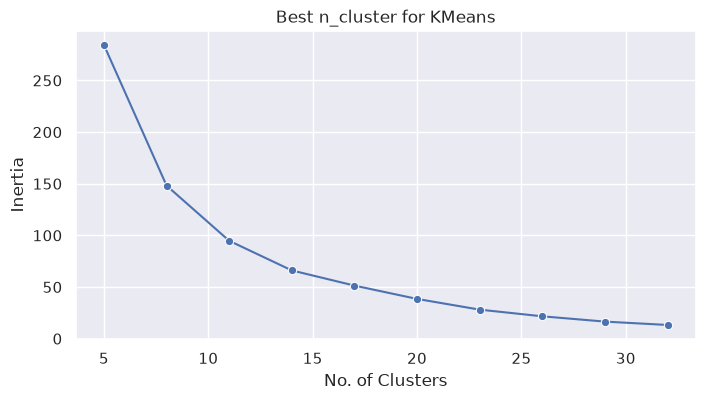

In [85]:
from sklearn.cluster import KMeans

cluster = range(5, 35, 3)
inertias = []

for k in cluster:
    model = KMeans(n_clusters=k, random_state=73)
    model.fit(df_copy[['Latitude', 'Longitude']])
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=cluster, y=inertias, marker='o')
plt.title('Best n_cluster for KMeans')
plt.xlabel('No. of Clusters')
plt.ylabel('Inertia')
plt.show();

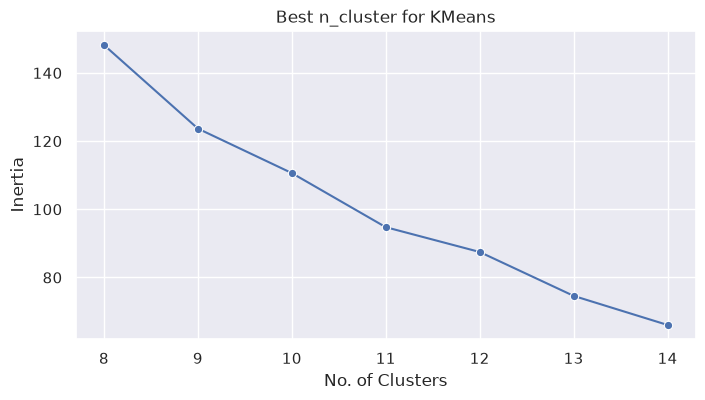

In [86]:
cluster = range(8, 15)
inertias = []

for k in cluster:
    model = KMeans(n_clusters=k, random_state=73)
    model.fit(df_copy[['Latitude', 'Longitude']])
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=cluster, y=inertias, marker='o')
plt.title('Best n_cluster for KMeans')
plt.xlabel('No. of Clusters')
plt.ylabel('Inertia')
plt.show();

In [87]:
model = KMeans(n_clusters=11, random_state=73)
model.fit_predict(df_copy[['Latitude', 'Longitude']])
df_copy['cluster'] = model.labels_
df_copy[['Location', 'cluster']].head()

,Location,cluster
0,"Santo Domingo, Cainta",9
1,"San Vicente, Santa Maria",9
2,"Camella Tarlac Access Rd. Maliwalo, Tarlac",0
3,"Gabon, Abucay",0
4,"Zambowood Rd. Boalan, Zamboanga",5


<Axes: xlabel='log_price'>

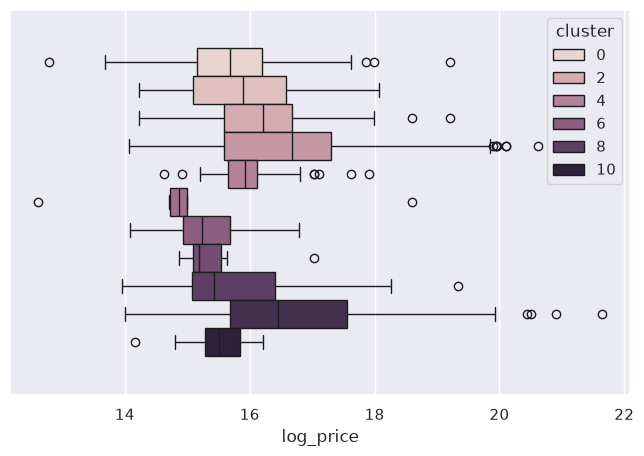

In [92]:
data = df_copy[['Price', 'cluster']]
data['log_price'] = np.log1p(data['Price'])

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='log_price', hue='cluster')

## Data Cleaning

In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HouseID      1500 non-null   int64  
 1   Description  1500 non-null   str    
 2   Location     1497 non-null   str    
 3   Price        1451 non-null   float64
 4   Bedrooms     1437 non-null   float64
 5   Bathrooms    1420 non-null   float64
 6   Floor Area   1463 non-null   float64
 7   Land Area    1477 non-null   float64
 8   Latitude     1500 non-null   float64
 9   Longitude    1500 non-null   float64
dtypes: float64(7), int64(1), str(2)
memory usage: 278.2 KB


It is observed that there are a number of columns that has a null value. There is no duplicated rows in the dataset. We will start first with the null values in Price. Since it is the target variable, we cannot impute a value with it. We have to drop the null values.

In [66]:
# Drop Null Prices

df = df.dropna(subset=['Price'])

In [67]:
df.isnull().sum()

HouseID         0
Description     0
Location        3
Price           0
Bedrooms       62
Bathrooms      78
Floor Area     35
Land Area      21
Latitude        0
Longitude       0
dtype: int64

Next is the location since it has the next smallest number of null values. Let's observe the values first

In [68]:
pd.set_option("display.max_colwidth", None)
df.loc[df['Location'].isnull()]

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
159,160,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Typical End Unit (Garden Unit)",NaN,28376000.0,3.0,3.0,219.3,106.0,14.432163,121.045242
296,297,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Unit Facing Clubhouse",NaN,34016000.0,3.0,3.0,247.4,93.0,14.432163,121.045242
300,301,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Typical Unit (Garden Unit)",NaN,27088000.0,3.0,3.0,219.3,90.0,14.432163,121.045242


In [69]:
# Impute Location

df.loc[df['Location'].isna(), 'Location'] = 'Likha Residences, Muntinlupa'

In [70]:
df.iloc[[155, 292, 296], :]

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
159,160,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Typical End Unit (Garden Unit)","Likha Residences, Muntinlupa",28376000.0,3.0,3.0,219.3,106.0,14.432163,121.045242
296,297,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Unit Facing Clubhouse","Likha Residences, Muntinlupa",34016000.0,3.0,3.0,247.4,93.0,14.432163,121.045242
300,301,"3BR 3-Storey Townhouse for Sale near Alabang in Likha Residences, Muntinlupa | Typical Unit (Garden Unit)","Likha Residences, Muntinlupa",27088000.0,3.0,3.0,219.3,90.0,14.432163,121.045242


The null locations are observed to be all from Likha Residences, Muntinlupa based on the description. For simplicity, we have directly hardcoded the imputation for this null location. However, for a larger project with a lot of null locations, the analyst need to design the imputation programmatically based on a pattern on how to get the address from the description.

In [71]:
df.isnull().sum()

HouseID         0
Description     0
Location        0
Price           0
Bedrooms       62
Bathrooms      78
Floor Area     35
Land Area      21
Latitude        0
Longitude       0
dtype: int64

Lets look at the data first for all the remaining null values

In [72]:
# Bathrooms

df.loc[df['Bathrooms'].isnull()].sample(n=10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
1322,1323,"L-R-1-1295: Acquired Property House and Lot for Sale in Lot 17, Block 12, Apo St., Brgy. Mabini Homesite, Cabanatuan City, Nueva Ecija","Lot 17, Block 12, Apo St., Brgy. Mabini Homesite, Cabanatuan City, Nueva Ecija Mabini Homesite, Cabanatuan",1412800.0,1.0,NaN,64.0,180.0,15.478573,120.977895
1314,1315,"L-R-1-1000- Acquired Property for Sale in Lot 9, Block 236, Vermillon Drive, Mabuhay City Subdivision, Phase 1-E, Brgy. Mamatid, Cabuyao City, Laguna","Mamatid, Cabuyao",1189675.0,NaN,NaN,72.3,81.0,14.235037,121.151888
1351,1352,"V-R-2-113: Acquired Property for Sale in Lot 18 and 20, Block 3, Road Lot 3, Edzaville Subdivision, Brgy. Binicuil, Kabankalan, Negros Occidental","Binicuil, Kabankalan",4202000.0,NaN,NaN,170.1,200.0,10.021640,122.822478
882,883,"L-R-1-829- Acquired Property for Sale in Lot 3, Block 1, Road Lot 3, Woodlands Subd., Brgy. Viga, Calamba City, Laguna - Retail","Makiling, Calamba",3354800.0,NaN,NaN,149.0,132.0,14.154413,121.136803
1163,1164,"V-R-2-107: Acquired Property for Sale in Lot 28, Block 7, Camella Savannah, Brgy. Abilay Norte / Polo Maestra Vita, Oton, Iloilo","Polo Maestra Bita, Oton",4219500.0,NaN,NaN,123.0,191.0,10.741526,122.506208
1301,1302,"L-R-1-591- Acquired Property for Sale in Lot 1292-B-1-C-2, Pablico St., Anonuevo Subdivision, Brgy. Pinagsanjan, Pagsanjan, Laguna - Retail","Pinagsanjan, Pagsanjan",3522000.0,NaN,NaN,160.0,156.0,14.268239,121.458199
1371,1372,"V-R-2-102: Acquired Property for Sale in Lot 29, Block 7, Road Lot 2, Golden River Village, Brgy. Taculing, Bacolod City, Negros Occidental","Taculing, Bacolod",2663200.0,NaN,NaN,90.0,96.0,10.647965,122.952962
970,971,"3BR Townhouse in Sampaloc, Manila City For Sale near UST Manila","M Dela Fuente Sampaloc Manila Sampaloc, Manila",13000000.0,3.0,NaN,130.0,50.0,14.614296,120.991122
1087,1088,"L-R-1-693- Acquired Property for Sale in Lot 1, Block 1, Via Romania St., Roma - Citta Italia, Brgy. Molino, Bacoor City, Cavite - Retail","Molino Iii, Bacoor",11058400.0,NaN,NaN,327.0,239.0,14.398172,120.978222
956,957,"L-R-1-784- Acquired Property for Sale in Lot 16, Block 5, Alley 2, Road Lot 5, Villa Clara Homes, Brgy. San Sebastian, Hagonoy, Bulacan - Retail","San Sebastian, Hagonoy",4377000.0,NaN,NaN,215.0,196.0,14.832172,120.734937


In [73]:
# Bedroom

df.loc[df['Bedrooms'].isnull()].sample(n=10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
1086,1087,"L-R-1-472- Acquired Property for Sale in Lot 3797-D, Brgy. Magtaquing / Paitan, San Carlos City, Pangasinan - Retail","Paitan-Panoypoy, San Carlos",10400000.0,NaN,NaN,417.0,2467.0,15.915975,120.347797
1417,1418,"L-R-1-873- Acquired Property for Sale in Lot 6014 Cad-381-D, Brgy. Nambalan, Santa Ignacia, Tarlac - Retail","Nambalan, Santa Ignacia",359600.0,NaN,NaN,64.0,334.0,15.600566,120.459403
368,369,"Springfield View | Walnut Basic House and Lot for Sale in Tanza, Cavite | Futura by Filinvest","Remulla Drive Tanza-Naic Rd. Sahud Ulan, Tanza",5820400.0,NaN,NaN,67.5,100.0,14.363135,120.820776
1408,1409,"L-R-1-900- Acquired Property for Sale in Lot 15159, Pinsal Falls Road, Brgy. Laslasong Sur, Santa Maria, Ilocos Sur","Laslasong Sur, Santa Maria",4763300.0,NaN,NaN,225.0,1382.0,17.388063,120.494962
1451,1452,"L-R-1-373- Acquired Property for Sale in Lot 38, Block 10, Road Lot 3, Celina Homes Technopark Subdivision, Brgy. Loma, Bi","Loma, Binan",2000000.0,NaN,NaN,115.0,63.0,14.281300,121.064443
35,36,"Springfield View | Molave House and Lot for Sale in Tanza, Cavite | Futura by Filinvest","Remulla Drive Tanza-Naic Rd. Sahud Ulan, Tanza",3167300.0,NaN,NaN,39.6,100.0,14.363135,120.820776
1155,1156,"Townhouse For Sale! Foreclosed Property! in BF Resort Village, Las Piñas City","Talon Dos, Las Pinas",5250000.0,NaN,NaN,93.0,52.0,14.433089,120.984705
1077,1078,"N-R-1-81: Acquired Property for Sale in Lot 53, Block 11, Camella Homes Subdivision, Phase II / Expansion, Brgy. San Isidro, General Santos City, South Cotabato","San Isidro, General Santos City",2456000.0,NaN,NaN,70.0,88.0,6.143747,125.179168
111,112,"Ready For You: Townhouse for Sale in Capas, Tarlac at Ajoya Capas","Talaga, Capas",2351000.0,NaN,2.0,49.0,50.0,15.383744,120.587083
1163,1164,"V-R-2-107: Acquired Property for Sale in Lot 28, Block 7, Camella Savannah, Brgy. Abilay Norte / Polo Maestra Vita, Oton, Iloilo","Polo Maestra Bita, Oton",4219500.0,NaN,NaN,123.0,191.0,10.741526,122.506208


In [74]:
# Floor Area

df.loc[df['Floor Area'].isnull()].sample(n=10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
791,792,"San Lorenzo Village 2 Storey House 5 Bedroom for Sale, Makati City","San Lorenzo, Makati",200000000.0,5.0,5.0,NaN,470.0,14.550877,121.020783
1244,1245,Capitol 8 House and Lot for Sale! Pasig City,"Kapitolyo, Pasig",120000000.0,3.0,3.0,NaN,444.0,14.571165,121.059498
609,610,"For sale: 5 bedroom House in San Luis, Baguio City","San Luis Village, Baguio City, Cordillera Administrative Region, Philippines San Luis Village, Baguio",10000000.0,5.0,3.0,NaN,250.0,16.409373,120.563323
1242,1243,"Bungalow House for SALE in West Kamias, Quezon City","West Kamias, Quezon City",28000000.0,6.0,2.0,NaN,300.0,14.630559,121.049540
1473,1474,House and Lot For Sale in Manito Albay,"It-Ba, Manito",25000000.0,7.0,5.0,NaN,573.0,13.124270,123.869183
822,823,For Sale : 3 Bedroom House & Lot at Scout Area in Quezon City,"Sacred Heart, Quezon City",66060000.0,3.0,2.0,NaN,367.0,14.631391,121.038916
29,30,"House and Lot for Sale in Highlands Subdivision, Brgy. Palo-Alto, Calamba Laguna","Palo-Alto, Calamba",3500000.0,NaN,NaN,NaN,104.0,14.183955,121.107290
1283,1284,"Ayala Alabang Village, Muntinlupa City | 5BR House and Lot For Sale","Ayala Alabang, Muntinlupa",158000000.0,5.0,NaN,NaN,600.0,14.422610,121.026941
896,897,House and Lot in Teachers Village,"Teachers Village East, Quezon City",33000000.0,3.0,NaN,NaN,412.0,14.644231,121.059698
1108,1109,House & Lot for Sale in Marikina City,"Concepcion Dos, Marikina",12000000.0,3.0,2.0,NaN,240.0,14.640589,121.120818


In [75]:
# Land Area

df.loc[df['Land Area'].isnull()].sample(n=10, random_state=73)

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
71,72,"3BR House and Lot for Sale in San Jose, Batangas at PHINMA Maayo San Jose | Salva Premier, 500K Discount Promo + Appliance Bundle!","President Jose P. Laurel Hwy Banaybanay Ii, San Jose",7400000.0,3.0,3.0,125.0,NaN,13.918423,121.105495
1223,1224,Francis Court Townhouse | Five Bedroom Townhouse for Sale at San Juan - #5842,"Pasadena, San Juan",57000000.0,5.0,4.0,385.0,NaN,14.608727,121.033251
95,96,"Ready For You: 1BR SA House and Lot (Ananda) for Sale in Compostela, Cebu at Amoa at Php 90,416 monthly amortization","Tamiao, Compostela",5580000.0,1.0,1.0,NaN,NaN,10.438288,123.994725
954,955,5 Bedrooms House and Lot For Sale in Tagum City,"Visayan Village, Tagum",8005320.0,5.0,3.0,100.0,NaN,7.431843,125.803791
1036,1037,"New in the market ! For Sale Luntala Townhouse in Valle Verde 7, Pasig","Ugong, Pasig",55000000.0,4.0,3.5,208.0,NaN,14.584131,121.073246
1157,1158,"Rush Sale! House and Lot Property in San Lorenzo Village, Makati City","9 Rocha, Makati, 1223 Kalakhang Maynila San Lorenzo, Makati",179000000.0,3.0,3.0,448.0,NaN,14.548714,121.016856
662,663,Ayala Alabang House For Sale,Muntinlupa,185000000.0,NaN,NaN,NaN,NaN,14.389263,121.044910
1045,1046,2 Bedroom House and Lot for Sale at Casa Segovia in Bulacan (Duplex 44.50 sqm),"Hinukay, Baliuag",1668179.0,2.0,1.0,44.5,NaN,15.009299,120.883355
164,165,"1BR House and Lot for Sale in Mexico, Pampanga | Flavorscapes at The Lakeshore, Duo Work Live","Divisoria, Mexico",1635170.0,1.0,1.0,78.7,NaN,14.432163,121.045242
130,131,"3BR House and Lot for Sale in Mexico, Pampanga | Parklane at The Lakeshore, Hyde","San Rafael, Mexico",2705850.0,3.0,2.0,77.3,NaN,15.087496,120.674239


Looking at the data, we cannot get a general imputation strategy from the description just like how it was made for missing location. There are several ways to handle with this with a simple median value imputation. It can be acceptable for small percentage of data although many of it would misrepresent its row since it can have a value per say 3 bedrooms but a very small floor or land area. We can also do a linear regression model to impute missing value based on another given data that is present in the row but that would require us to create a linear regression model for each of the column and that would a little bit complicate our task.

For bathroom and bedroom, we will get the median number of rooms depending on floor area (bins). Then impute it to the missing value. For the missing floor area and land area, we will calculate the ratio and get the median, then use the median to impute the missing value. If there is still missing left in the column, we will impute it with the median for the column.

In [76]:
df['floor_bin'] = pd.qcut(df['Floor Area'], q=10, duplicates='drop')

bedroom_medians = df.groupby('floor_bin', observed=True)['Bedrooms'].median()
bathroom_medians = df.groupby('floor_bin', observed=True)['Bathrooms'].median()

df['Bedrooms'] = df['Bedrooms'].fillna(df['floor_bin'].map(bedroom_medians))
df['Bathrooms'] = df['Bathrooms'].fillna(df['floor_bin'].map(bathroom_medians))

df['Bedrooms'] = df['Bedrooms'].fillna(df['Bedrooms'].median())
df['Bathrooms'] = df['Bathrooms'].fillna(df['Bathrooms'].median())

In [77]:
ratio = (df['Floor Area'] / df['Land Area']).median()

df['Floor Area'] = df['Floor Area'].fillna(df['Land Area'] * ratio)
df['Land Area'] = df['Land Area'].fillna(df['Floor Area'] / ratio)

df['Floor Area'] = df['Floor Area'].fillna(df['Floor Area'].median())
df['Land Area'] = df['Land Area'].fillna(df['Land Area'].median())

In [78]:
df = df.drop(columns=['floor_bin'])

In [79]:
df.isnull().sum()

HouseID        0
Description    0
Location       0
Price          0
Bedrooms       0
Bathrooms      0
Floor Area     0
Land Area      0
Latitude       0
Longitude      0
dtype: int64

In [80]:
df.head()

,HouseID,Description,Location,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
0,1,"Preselling 2-Storey Townhouses in Village East Executive Subdivision, Cainta","Santo Domingo, Cainta",9500000.0,4.0,3.0,144.0,136.0,14.582341,121.118044
1,2,"Affordable House & Lot with Complete Amenities for Sale in Santa Maria, Bulacan","San Vicente, Santa Maria",4400000.0,3.0,2.0,63.2,80.0,14.807715,121.002402
2,3,5BR 2-Storey House and Lot for Sale in Tarlac City at Camella Tarlac | Ella 110sqm,"Camella Tarlac Access Rd. Maliwalo, Tarlac",7810000.0,5.0,3.0,100.0,110.0,15.477785,120.614075
4,5,Futura Homes Zamboanga | Amber 2BR Townhouse End Unit for Sale in Zamboanga City | Futura by Filinvest,"Zambowood Rd. Boalan, Zamboanga",3275000.0,2.0,1.0,40.3,78.4,6.948389,122.114889
5,6,"Springfield View | Molave House and Lot for Sale in Tanza, Cavite | Futura by Filinvest","Remulla Drive Tanza-Naic Rd. Sahud Ulan, Tanza",3167300.0,2.0,1.0,39.6,100.0,14.363135,120.820776


In [81]:
df.describe()

,HouseID,Price,Bedrooms,Bathrooms,Floor Area,Land Area,Latitude,Longitude
count,1451.000000,1.451000e+03,1451.000000,1451.000000,1451.000000,1451.000000,1451.000000,1451.000000
mean,747.561682,3.282218e+07,3.587181,2.939697,214.681958,249.878090,14.171388,121.249646
std,434.531998,1.012451e+08,1.328136,1.475425,235.305250,601.886283,1.853809,1.048834
min,1.000000,3.000000e+05,1.000000,1.000000,22.000000,27.000000,6.128079,119.861430
25%,367.500000,4.902000e+06,3.000000,2.000000,70.000000,80.000000,14.333530,120.863963
50%,747.000000,9.200000e+06,3.000000,3.000000,142.000000,121.000000,14.533049,121.026941
75%,1122.500000,2.500000e+07,4.000000,4.000000,250.000000,240.000000,14.913178,121.085187
max,1500.000000,2.500000e+09,13.000000,13.000000,2200.000000,10000.000000,17.630468,125.803791


## EDA Conclusion

We have finished the exploratory data analysis and now we are ready for feature engineering. In EDA, the relationships between features and target variable are observed. Patterns were also recognized resulting for engineered features that might help the model predict house prices. The process of cleaning the data is also materialized by using the observations from the data. 